# Ataques Adversariais: Comprometendo Sistemas Baseados em Machine Learning

## Importações

In [57]:
!pip install gdown

import gdown

In [56]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from PIL import Image
import matplotlib.pyplot as plt
import os
import random
import numpy as np
import zipfile
import shutil

## Carregamento de Dados

In [58]:
!gdown --folder https://drive.google.com/drive/folders/1ZJIITWgAplI4_Aohj_Hw5Nuz9KEw_ZhM

Retrieving folder contents
Processing file 1gVmNAc_uvFR7ujpd4TAZQ533yr-X1dmp cats_dogs_small.zip
Processing file 1eSkfzfI50ayZJvMPZp2XPCSXqt4Qu1JC glasses_no_glasses.zip
Processing file 1VNwAt5AHWoKXuwhCrE1uiTpAk_rKQFBh mask_no_mask.zip
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From (original): https://drive.google.com/uc?id=1gVmNAc_uvFR7ujpd4TAZQ533yr-X1dmp
From (redirected): https://drive.google.com/uc?id=1gVmNAc_uvFR7ujpd4TAZQ533yr-X1dmp&confirm=t&uuid=90aa7222-a7c7-4e23-b32a-d2ab38e521b6
To: /content/Data/cats_dogs_small.zip
100% 32.3M/32.3M [00:01<00:00, 28.6MB/s]
Downloading...
From: https://drive.google.com/uc?id=1eSkfzfI50ayZJvMPZp2XPCSXqt4Qu1JC
To: /content/Data/glasses_no_glasses.zip
100% 3.96M/3.96M [00:00<00:00, 23.7MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1VNwAt5AHWoKXuwhCrE1uiTpAk_rKQFBh
From (redirected): https://drive.google.com/uc?id=1VNwAt5AHWoKXuwhCrE1uiTpAk_rKQF

In [59]:
data_path = "/content/Data"

zip_files = [f for f in os.listdir(data_path) if f.endswith(".zip")]

print("Datasets disponíveis:\n")
for i, file in enumerate(zip_files, 1):
    print(f"{i} - {file}")

choice = input("\nDigite o número do dataset: ")

try:
    choice = int(choice)
    selected_zip = zip_files[choice - 1]
except:
    raise ValueError("Opção inválida!")

zip_path = os.path.join(data_path, selected_zip)

extract_path = os.path.join(data_path, selected_zip.replace(".zip", ""))
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

extract_name = os.path.basename(os.path.normpath(extract_path))
subdirs = [d for d in os.listdir(extract_path) if os.path.isdir(os.path.join(extract_path, d))]
nested_path = os.path.join(extract_path, extract_name)
class_subdirs = [d for d in subdirs if d != extract_name]

if os.path.isdir(nested_path) and class_subdirs:
    shutil.rmtree(nested_path)
    subdirs = class_subdirs
elif os.path.isdir(nested_path):
    subdirs = [extract_name]

if len(subdirs) == 1:
    inner_path = os.path.join(extract_path, subdirs[0])

    for item in os.listdir(inner_path):
        shutil.move(os.path.join(inner_path, item), extract_path)

    os.rmdir(inner_path)

print(f"\nDataset escolhido: {selected_zip}")
print(f"Extraído em: {extract_path}")

Datasets disponíveis:

1 - glasses_no_glasses.zip
2 - cats_dogs_small.zip
3 - mask_no_mask.zip

Dataset escolhido: cats_dogs_small.zip
Extraído em: /content/Data/cats_dogs_small


In [60]:
data_dir = extract_path

In [61]:
IMG_SIZE = (160, 160)
BATCH_SIZE = 32

train_ds, val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="both",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)



Found 1000 files belonging to 2 classes.


Using 800 files for training.
Using 200 files for validation.


In [62]:
print(train_ds.class_names)

['cats', 'dogs']


## Modelo de Classificação

In [63]:
IMG_SHAPE = IMG_SIZE + (3,)
base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SHAPE, include_top=False, weights='imagenet')
base_model.trainable = False

model = tf.keras.Sequential([
    tf.keras.layers.Rescaling(1./255),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [64]:
model.fit(train_ds, validation_data=val_ds, epochs=3)

Epoch 1/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 29s 919ms/step - accuracy: 0.7613 - loss: 0.4738 - val_accuracy: 0.9350 - val_loss: 0.2285
Epoch 2/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 45s 1s/step - accuracy: 0.9375 - loss: 0.1836 - val_accuracy: 0.9600 - val_loss: 0.1476
Epoch 3/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 22s 866ms/step - accuracy: 0.9563 - loss: 0.1316 - val_accuracy: 0.9650 - val_loss: 0.1221


In [65]:
model.evaluate(val_ds)

7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 505ms/step - accuracy: 0.9650 - loss: 0.1221


[0.12211623787879944, 0.9649999737739563]

## Mostrando as imagens

In [30]:
class_names = [d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))]

paths = []

class_names = sorted(class_names)

for class_name in class_names:
    class_dir = os.path.join(data_dir, class_name)

    images = [f for f in os.listdir(class_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

    if not images:
        continue

    chosen = random.choice(images)
    full_path = os.path.join(class_dir, chosen)

    paths.append(full_path)

if len(paths) >= 2:
    path_class1 = paths[0]
    path_class2 = paths[1]

print("Classe 1:", path_class1)
print("Classe 2:", path_class2)

Classe 1: /content/Data/cats_dogs_small/cats/2334.jpg
Classe 2: /content/Data/cats_dogs_small/dogs/5959.jpg


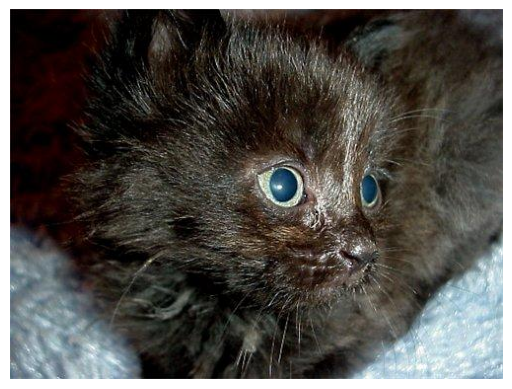

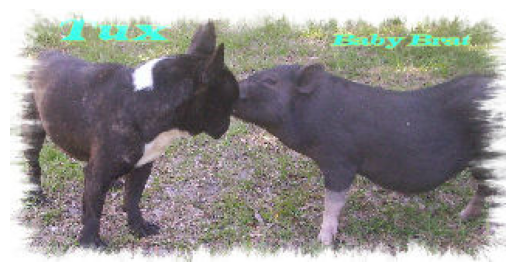

In [31]:
img_cat = Image.open(path_class1)
plt.imshow(img_cat)
plt.axis('off')
plt.show()

img_dog = Image.open(path_class2)
plt.imshow(img_dog)
plt.axis('off')
plt.show()

## Realizando a inferência

In [66]:
def predict_image(path, model, class_names):
    img = tf.keras.utils.load_img(path, target_size=(160,160))
    img = tf.keras.utils.img_to_array(img)

    img = tf.expand_dims(img, axis=0)

    pred = model.predict(img, verbose=0)[0][0]

    pred_class = int(pred >= 0.5)
    class_name = class_names[pred_class]

    confidence = pred if pred_class == 1 else 1 - pred

    return img, pred, class_name, confidence

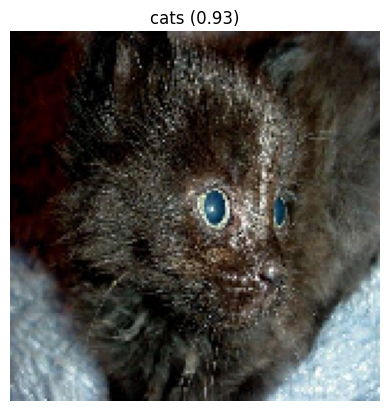

In [33]:
img, pred, classe, conf = predict_image(path_class1, model, class_names)

plt.imshow(img[0].numpy().astype("uint8"))
plt.title(f"{classe} ({conf:.2f})")
plt.axis('off')
plt.show()

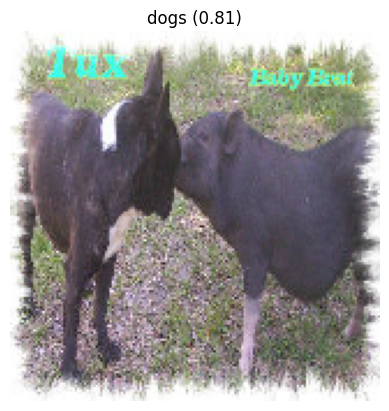

In [15]:
img, pred, classe, conf = predict_image(path_class2, model, class_names)

plt.imshow(img[0].numpy().astype("uint8"))
plt.title(f"{classe} ({conf:.2f})")
plt.axis('off')
plt.show()

# Ataques Iterativos - WhiteBox
## Bem-vindo ao CleverHans!

https://github.com/cleverhans-lab/cleverhans

## Instalando a biblioteca

In [55]:
! pip install cleverhans

## BIM

### Importando o ataque iterativo

In [17]:
from cleverhans.tf2.attacks.basic_iterative_method import basic_iterative_method

### Gerando o Exemplo Adversarial

In [ ]:


desired_class = 0  # escolha 0 ou 1

for images, labels in val_ds.unbatch():
    if labels.numpy() == desired_class:
        x_input = tf.cast(tf.expand_dims(images, 0), tf.float32)
        y_true_ch = tf.cast(tf.reshape([labels], [-1]), tf.int32)
        break

In [19]:
def model_wrapper(x):
    prob_1 = model(x)
    prob_0 = 1.0 - prob_1
    return tf.concat([prob_0, prob_1], axis=1)

_ = model_wrapper(x_input)

In [ ]:
# Craft adversarial sample

eps = 8.0
eps_iter = 1.0
nb_iter = 15

adv_x_bim = basic_iterative_method(model_fn=model_wrapper, x=x_input, eps=eps, eps_iter=eps_iter, nb_iter=nb_iter, norm=np.inf, clip_min=0.0, clip_max=255.0, y=y_true_ch, sanity_checks=False)

### Realizando a classificação do exemplo adversarial


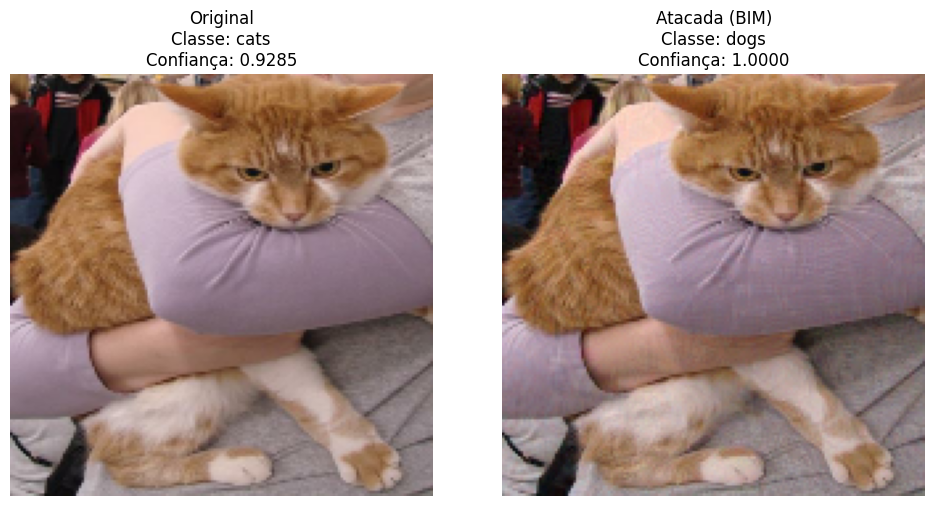

In [21]:
# Classify adversarial sample and print classification result

pred_orig = model.predict(x_input, verbose=0)[0][0]
pred_adv  = model.predict(adv_x_bim, verbose=0)[0][0]

def get_label_and_conf(p):
    label = class_names[1] if p > 0.5 else class_names[0]
    conf = p if p > 0.5 else 1 - p
    return label, conf

label_o, conf_o = get_label_and_conf(pred_orig)
label_a, conf_a = get_label_and_conf(pred_adv)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(tf.cast(x_input[0], tf.uint8).numpy())
plt.title(f"Original\nClasse: {label_o}\nConfiança: {conf_o:.4f}")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(tf.cast(adv_x_bim[0], tf.uint8).numpy())
plt.title(f"Atacada (BIM)\nClasse: {label_a}\nConfiança: {conf_a:.4f}")
plt.axis('off')

plt.tight_layout()
plt.show()

### Exibindo uma aproximação da perturbação

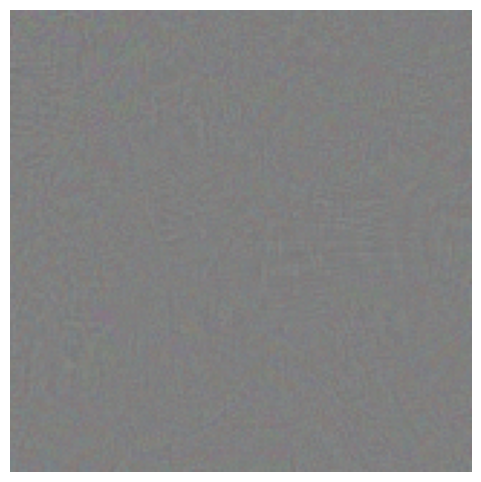

In [22]:
adv_f = adv_x_bim[0].numpy().astype('float32')
org_f = x_input[0].numpy().astype('float32')

perturbacao_real = adv_f - org_f

img_visualizacao = (perturbacao_real / 255.0) + 0.5

vmax = 0.1
vmin = -vmax

plt.figure(figsize=(6, 6))
plt.imshow(img_visualizacao, cmap='gray', vmin=vmin, vmax=vmax)
plt.axis('off')
plt.show()

## PGD


### Importando o ataque iterativo

In [23]:
from cleverhans.tf2.attacks.projected_gradient_descent import projected_gradient_descent

### Gerando o Exemplo Adversarial

In [ ]:
# Craft adversarial sample

eps = 8.0
eps_iter = 1.0
nb_iter = 15

adv_x_pgd = projected_gradient_descent(model_fn=model_wrapper, x=x_input, eps=eps, eps_iter=eps_iter, nb_iter=nb_iter,norm=np.inf, clip_min=0.0, clip_max=255.0, y=y_true_ch, rand_init=True, sanity_checks=False)

### Realizando a classificação do exemplo adversarial



--- RESULTADOS: PGD ---
ANTES: Classe = cats | Confiança = 0.9285
DEPOIS (PGD): Classe = dogs | Confiança = 1.0000


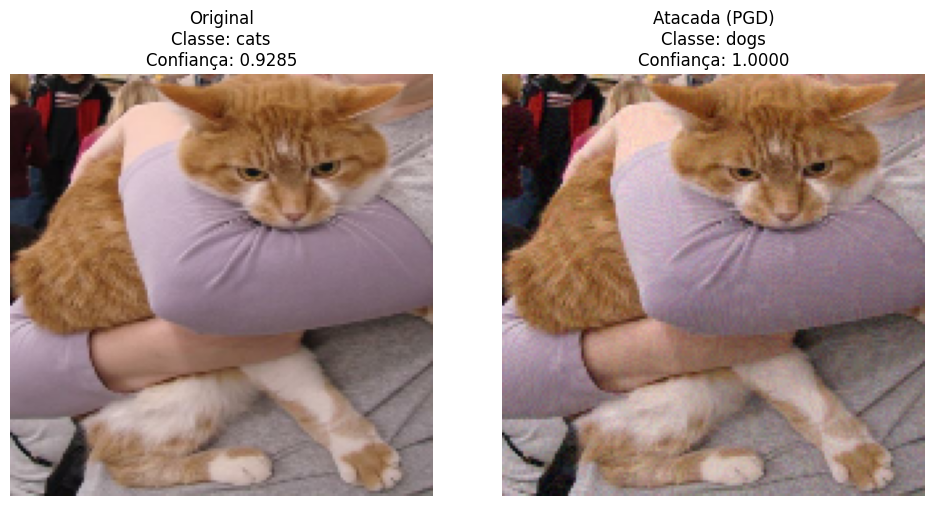

In [25]:
# Classify adversarial sample and print classification result

pred_orig = model.predict(x_input, verbose=0)[0][0]
pred_pgd  = model.predict(adv_x_pgd, verbose=0)[0][0]

class_names = train_ds.class_names

def get_label_and_conf(p):
    label = class_names[1] if p > 0.5 else class_names[0]
    conf = p if p > 0.5 else 1 - p
    return label, conf

label_o, conf_o = get_label_and_conf(pred_orig)
label_p, conf_p = get_label_and_conf(pred_pgd)

print("\n--- RESULTADOS: PGD ---")
print(f"ANTES: Classe = {label_o} | Confiança = {conf_o:.4f}")
print(f"DEPOIS (PGD): Classe = {label_p} | Confiança = {conf_p:.4f}")

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(tf.cast(x_input[0], tf.uint8).numpy())
plt.title(f"Original\nClasse: {label_o}\nConfiança: {conf_o:.4f}")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(tf.cast(adv_x_pgd[0], tf.uint8).numpy())
plt.title(f"Atacada (PGD)\nClasse: {label_p}\nConfiança: {conf_p:.4f}")
plt.axis('off')

plt.tight_layout()
plt.show()

### Exibindo uma aproximação da perturbação

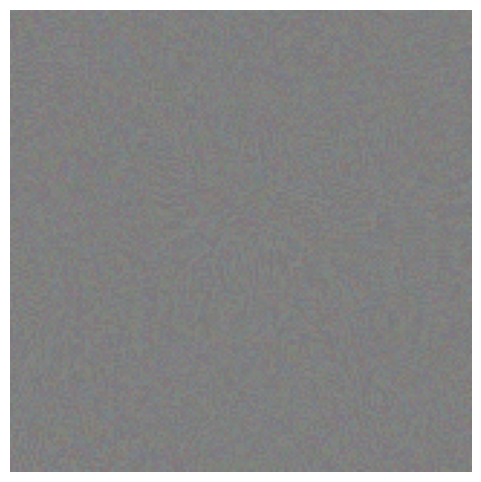

In [26]:
# Get and print adversarial perturbation
adv_f_pgd = adv_x_pgd[0].numpy().astype('float32')
org_f = x_input[0].numpy().astype('float32')

perturbacao_pgd = adv_f_pgd - org_f

img_viz_pgd = (perturbacao_pgd / 255.0) + 0.5

plt.figure(figsize=(6, 6))
plt.imshow(img_viz_pgd, cmap='gray', vmin=-0.1, vmax=0.1)
plt.axis('off')
plt.show()

## MIM

### Importando o ataque iterativo

In [27]:
from cleverhans.tf2.attacks.momentum_iterative_method import momentum_iterative_method

### Gerando o Exemplo Adversarial

In [ ]:
# Craft adversarial sample



eps = 8.0
eps_iter = 1.0
nb_iter = 15

adv_x_mim = momentum_iterative_method(model_fn=model_wrapper, x=x_input, eps=eps, eps_iter=eps_iter, nb_iter=nb_iter, decay_factor=1.0, norm=np.inf, clip_min=0.0, clip_max=255.0, y=y_true_ch, sanity_checks=False)

### Realizando a classificação do exemplo adversarial



--- RESULTADOS: MIM ---
ANTES: Classe = cats | Confiança = 0.9285
DEPOIS (MIM): Classe = dogs | Confiança = 1.0000


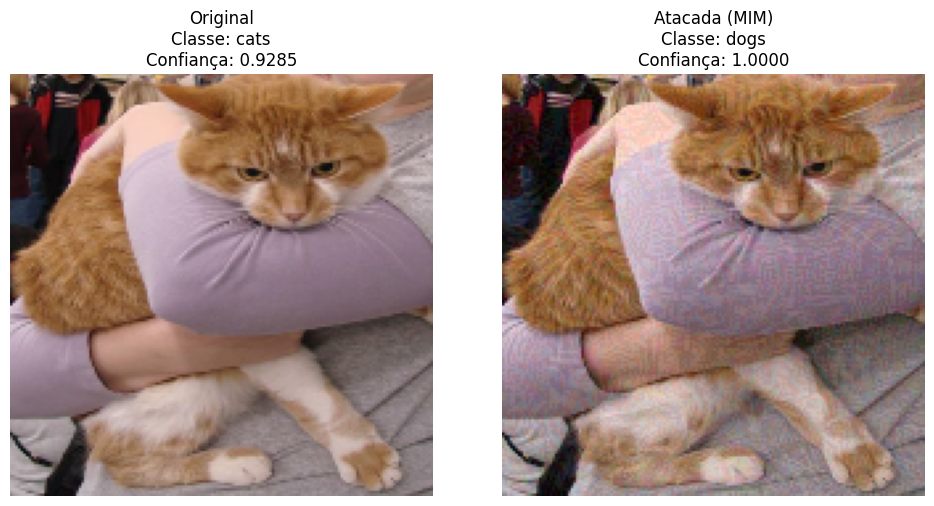

In [29]:
# Classify adversarial sample and print classification result

pred_orig = model.predict(x_input, verbose=0)[0][0]
pred_mim  = model.predict(adv_x_mim, verbose=0)[0][0]

class_names = train_ds.class_names

def get_label_and_conf(p):
    label = class_names[1] if p > 0.5 else class_names[0]
    conf = p if p > 0.5 else 1 - p
    return label, conf

label_o, conf_o = get_label_and_conf(pred_orig)
label_m, conf_m = get_label_and_conf(pred_mim)

print("\n--- RESULTADOS: MIM ---")
print(f"ANTES: Classe = {label_o} | Confiança = {conf_o:.4f}")
print(f"DEPOIS (MIM): Classe = {label_m} | Confiança = {conf_m:.4f}")

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(tf.cast(x_input[0], tf.uint8).numpy())
plt.title(f"Original\nClasse: {label_o}\nConfiança: {conf_o:.4f}")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(tf.cast(adv_x_mim[0], tf.uint8).numpy())
plt.title(f"Atacada (MIM)\nClasse: {label_m}\nConfiança: {conf_m:.4f}")
plt.axis('off')

plt.tight_layout()
plt.show()

### Exibindo uma aproximação da perturbação

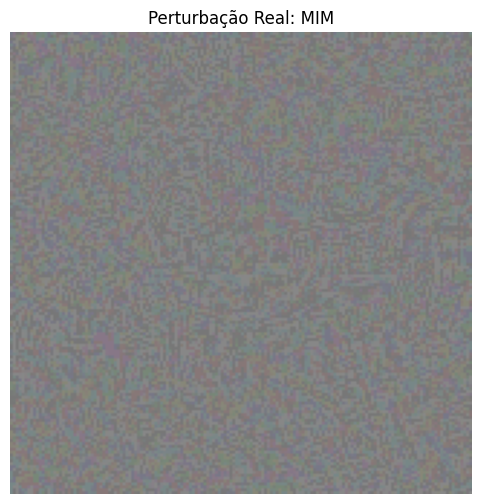

In [30]:
# Get and print adversarial perturbation
adv_f_mim = adv_x_mim[0].numpy().astype('float32')
org_f = x_input[0].numpy().astype('float32')

perturbacao_mim = adv_f_mim - org_f

img_viz_mim = (perturbacao_mim / 255.0) + 0.5

plt.figure(figsize=(6, 6))
plt.imshow(img_viz_mim, cmap='gray', vmin=-0.1, vmax=0.1)
plt.title("Perturbação Real: MIM")
plt.axis('off')
plt.show()

# Atividade Variação Paramétrica: BIM, PGD, MIM

**Etapa 1 — Comparando BIM, PGD e MIM:**

**Fixar:**
- `eps = 8`
- `eps_iter = 1`
- `nb_iter = 15`

Executar os três ataques sobre a mesma imagem.

Comparar:
- confiança antes e após o ataque

1. BIM:
    - Original: Clase = dogs | Confiança = 0.9549
    - Ataque: Classe = cats | Confiança: 0.9926
    - Sucesso
2. PGD: 
    - Original: Classe = dogs | Confiança = 0.9549
    - Ataque: Classe = cats | Confiança = 0.9986
3. MIM:
    - Original: Classe = dogs | Confiança = 0.9549
    - Ataque: Classe = cats | Confiança = 0.9982

**Etapa 2 — Estudar a magnitude de perturbação**

**Fixar:**
   - imagem
   - `eps_iter = 0.1`
   - `nb_iter = 20`

**Variar:**
   - `eps = [0.1, 0.2, 0.4, 0.8, 1.6]`


Para cada modelo, medir:
- taxa de sucesso;
- confiança média de amostras adversariais.

| **Objetivo:** Verificar quanto de perturbação é necessário para comprometer o modelo.

1. BIM:
    - Confiança média: 0.8124
    - Taxa de sucesso: 0.4000
2. PGD:
    - Confiança média: 0.7958
    - Taxa de sucesso: 0.4000
3. MIM:
    - Confiança média: 0.7919
    - Taxa de sucesso: 0.4000


**Etapa 3 — Estudar o impacto da iteração**

**Fixar:**
   - `eps_iter = 0.1`
   - `eps = 2.0`
   - imagem

**Variar**
   - `nb_iter = [3, 5, 7, 11, 13, 17]`

Para cada modelo, medir:
- taxa de sucesso;
- confiança média de amostras adversariais.

| **Objetivo:** Avaliar se mais iterações aumentam o sucesso ou apenas o custo computacional.

1. BIM:
    - Confiança média: 0.7349
    - Taxa de sucesso: 0.6667
2. PGD:
    - Confiança média: 0.7081
    - Taxa de sucesso: 0.5000
3. MIM:
    - Confiança média: 0.7098
    - Taxa de sucesso: 0.5000

**Etapa 4 — Aplicar Modelos de Ataques em Mais Imagens**

**Fixar:**
   - `eps_iter = 0.1`
   - `eps = 2.0`
   - `nb_iter = 30`

**Variar**
   - imagens: 2 primeiras do dataset de cada classe
    - São utilizados poucos exemplos, mas a ideia é dar uma demonstração.
   
Medir: taxa de sucesso, confiança média das amostras adversariais e magnitude da perturbação média por pixel

| **Objetivo**: Verificar se o comportamento observado nas etapas anteriores é específico de uma imagem ou se também aparece em diferentes exemplos e classes.

1. BIM:
    - Confiança média: 0.9918
    - Taxa de sucesso: 1.0000
    - Perturbação média: 1.1972
2. PGD:
    - Confiança média: 0.9854
    - Taxa de sucesso: 1.0000
    - Perturbação média: 1.3032
3. MIM:
    - Confiança média: 0.9780
    - Taxa de sucesso: 1.0000
    - Perturbação média: 1.6143     


## BIM

### Importando o ataque iterativo

In [67]:
from cleverhans.tf2.attacks.basic_iterative_method import basic_iterative_method

### Gerando o Exemplo Adversarial

In [237]:
def get_n_inputs(val_ds, desired_class, n=1):
    x_inputs = []
    y_trues = []
    for images, labels in val_ds.unbatch():
        if labels.numpy() == desired_class:
            x_input = tf.cast(tf.expand_dims(images, 0), tf.float32)
            y_true_ch = tf.cast(tf.reshape([labels], [-1]), tf.int32)
            x_inputs.append(x_input)
            y_trues.append(y_true_ch)
            if len(x_inputs) == n:
                return (x_inputs, y_trues)
    return (x_inputs, y_trues)

In [258]:

# 0 -> cats; 1 -> dogs
desired_class = 1  # escolha 0 ou 1

x_input, y_true_ch = get_n_inputs(val_ds, desired_class, n=1)
x_input = x_input[0]
y_true_ch = y_true_ch[0]

In [259]:
def model_wrapper(x):
    prob_1 = model(x)
    prob_0 = 1.0 - prob_1
    return tf.concat([prob_0, prob_1], axis=1)

_ = model_wrapper(x_input)

In [260]:
# Craft adversarial sample

eps = 0.1
eps_iter = 0.1
nb_iter = 20


In [261]:
adv_x_bim = basic_iterative_method(model_fn=model_wrapper, x=x_input, eps=eps, eps_iter=eps_iter, nb_iter=nb_iter, norm=np.inf, clip_min=0.0, clip_max=255.0, y=y_true_ch, sanity_checks=False, )

### Realizando a classificação do exemplo adversarial


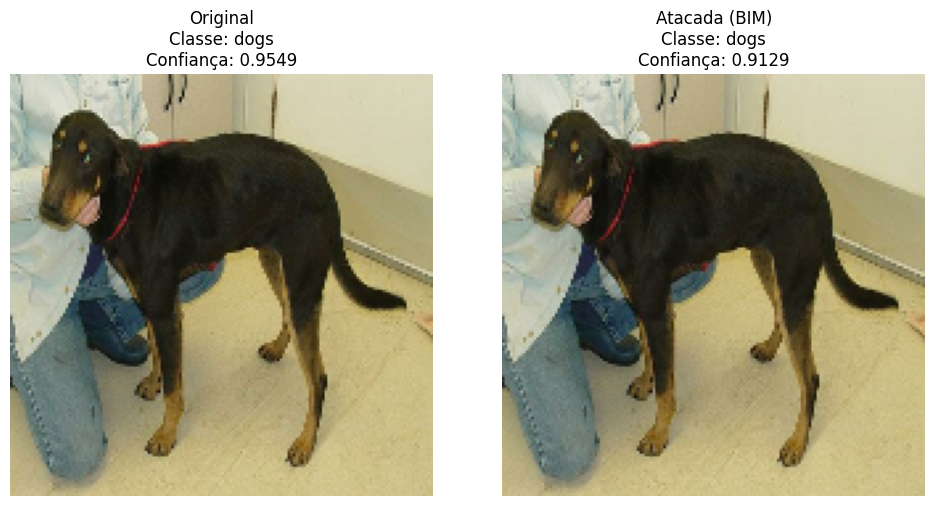

In [262]:
# Classify adversarial sample and print classification result

pred_orig = model.predict(x_input, verbose=0)[0][0]
pred_adv  = model.predict(adv_x_bim, verbose=0)[0][0]

def get_label_and_conf(p):
    label = class_names[1] if p > 0.5 else class_names[0]
    conf = p if p > 0.5 else 1 - p
    return label, conf

label_o, conf_o = get_label_and_conf(pred_orig)
label_a, conf_a = get_label_and_conf(pred_adv)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(tf.cast(x_input[0], tf.uint8).numpy())
plt.title(f"Original\nClasse: {label_o}\nConfiança: {conf_o:.4f}")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(tf.cast(adv_x_bim[0], tf.uint8).numpy())
plt.title(f"Atacada (BIM)\nClasse: {label_a}\nConfiança: {conf_a:.4f}")
plt.axis('off')

plt.tight_layout()
plt.show()

### Exibindo uma aproximação da perturbação

In [213]:
delta = adv_x_bim - x_input

max_perturbation = tf.reduce_max(tf.abs(delta)).numpy()
mean_perturbation = tf.reduce_mean(tf.abs(delta)).numpy()

print(f"Máxima perturbação L_inf: {max_perturbation:.4f}")
print(f"Perturbação média: {mean_perturbation:.4f}")

Máxima perturbação L_inf: 0.1000
Perturbação média: 0.0927


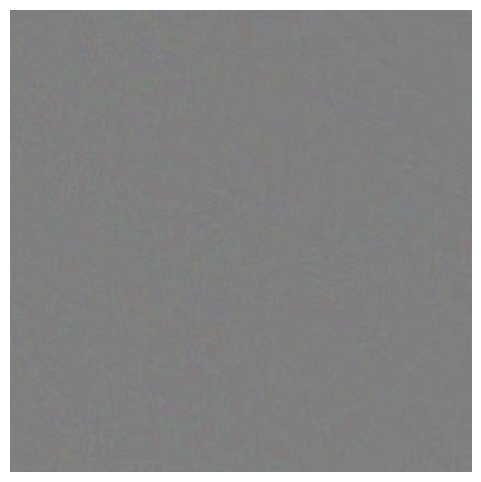

In [73]:
adv_f = adv_x_bim[0].numpy().astype('float32')
org_f = x_input[0].numpy().astype('float32')

perturbacao_real = adv_f - org_f

img_visualizacao = (perturbacao_real / 255.0) + 0.5

vmax = 0.1
vmin = -vmax

plt.figure(figsize=(6, 6))
plt.imshow(img_visualizacao, cmap='gray', vmin=vmin, vmax=vmax)
plt.axis('off')
plt.show()

### Variando hiperparâmetros BIM

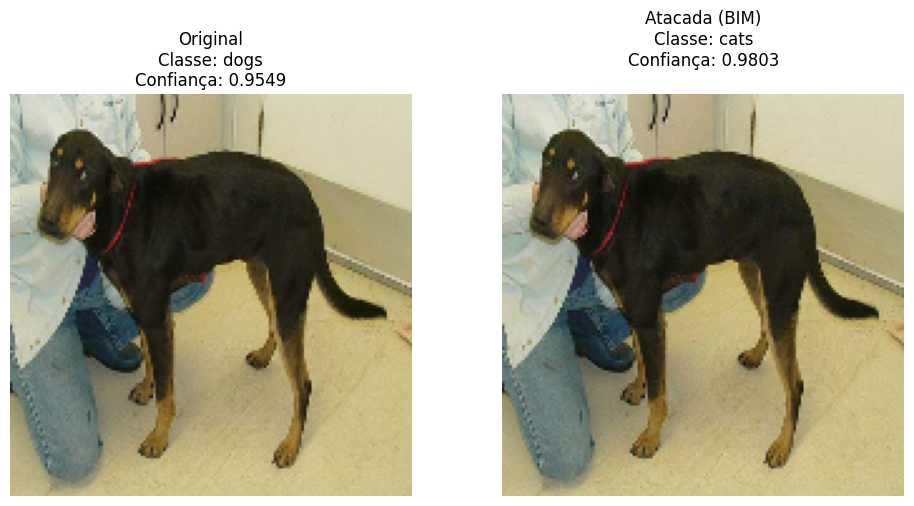

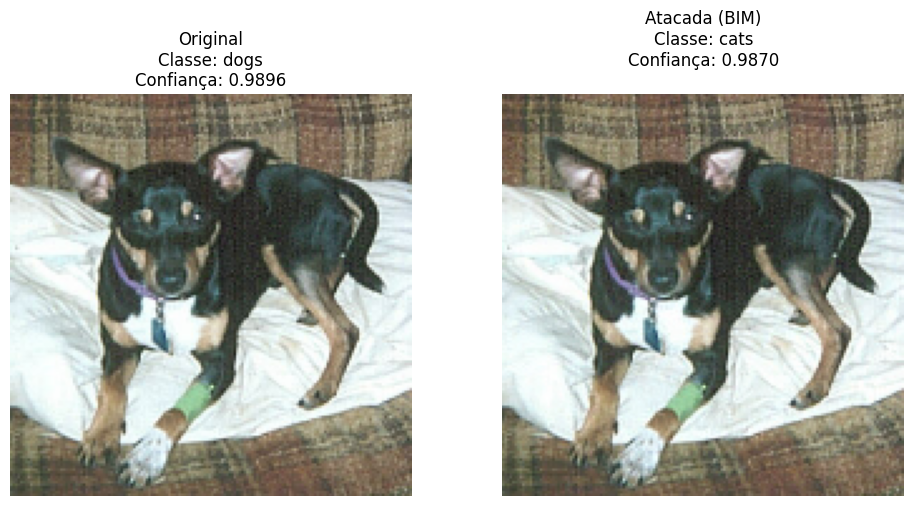

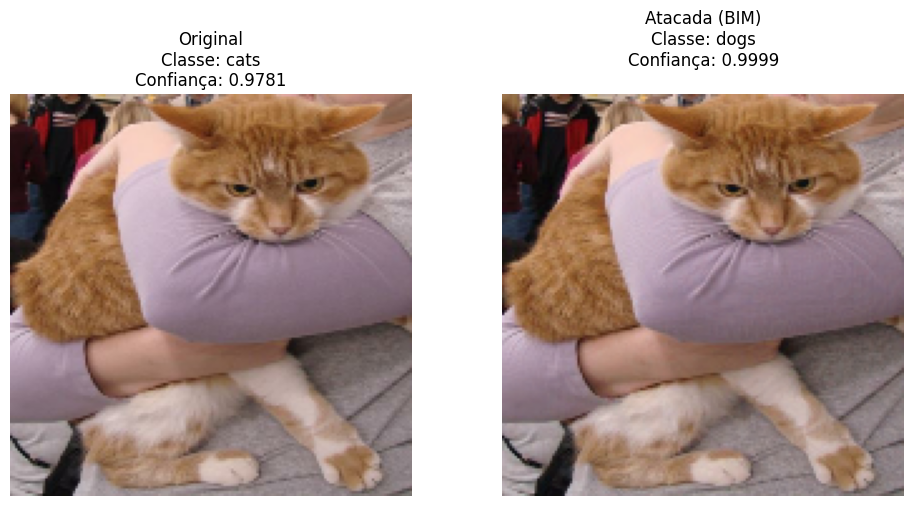

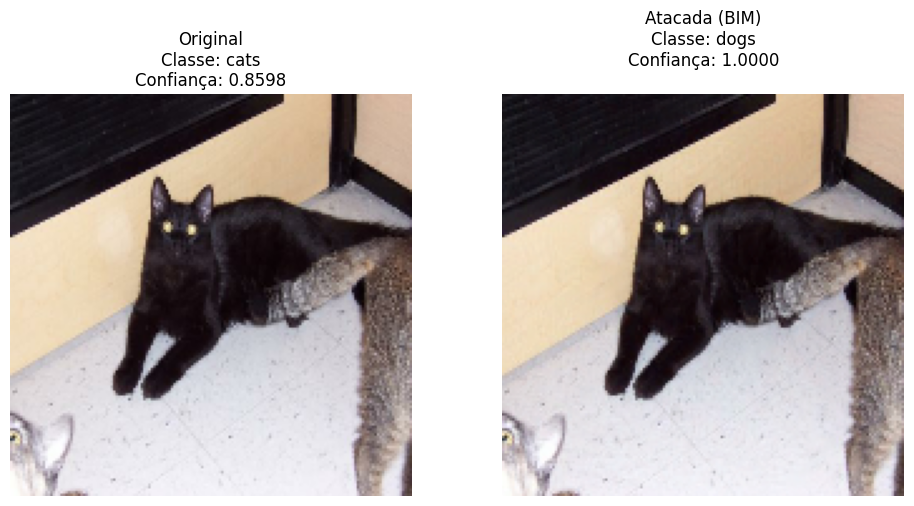

Confiança média das amostras adversariais: 0.9918
Taxa de sucesso: 1.0000
Perturbação média das amostras adversariais: 1.1972


In [274]:
### Codigo que repete o procedimento da etapa 2 de forma automatica
# 1. pega os parametros eps, eps_iter, nb_iter
# 2. pega o modelo e o input
# 3. gera adv_x para o ataque
# 4. calcula a perturbação delta, classe e confianca e coloca numa lista
# 5. salva a imagem na pasta de saida no padrao: img[num]_[modelo]_eps[num_float]_step[num_float]_iter[num_int]_[classe_desejada]-[resultado].png
#               ex.: img01_BIM_eps0.1_step0.1_iter20_dog-no-flip
#               resultado -> no-flip (nao mudou de classe) ou to-[classe adversarial] (mudou de classe) 
# 6. ao final da execucao para o ataque, calcula a taxa de sucesso (os que resultaram na classe diferente da desejada) e confianca media

from statistics import mean

# get samples
n_inputs = 2
x_dogs, y_dogs = get_n_inputs(val_ds, 1, n=n_inputs)
x_cats, y_cats = get_n_inputs(val_ds, 0, n=n_inputs)
# x_inputs = x_dogs + x_cats
# y_trues = y_dogs + y_cats
# x_input = x_dogs[n_inputs-1]
# y_true_ch = y_dogs[n_inputs-1]

eps = 2.0
eps_iter = 0.1
nb_iter = 30
# output_dir = 'adversarial_samples_ap7.2/etapa2_variacao-eps'
# os.makedirs(output_dir, exist_ok=True)


resultados = []
hparam_list = zip(x_dogs + x_cats, y_dogs + y_cats)
for hparam in hparam_list:
    x_input, y_true_ch = hparam

    # Classe da imagem original
    pred_orig = model.predict(x_input, verbose=0)[0][0]
    label_o, conf_o = get_label_and_conf(pred_orig)

    adv_x_bim = basic_iterative_method(model_fn=model_wrapper, x=x_input, eps=eps, eps_iter=eps_iter, nb_iter=nb_iter, norm=np.inf, clip_min=0.0, clip_max=255.0, y=y_true_ch, sanity_checks=False)
    
    delta = adv_x_bim - x_input
    max_perturbation = tf.reduce_max(tf.abs(delta)).numpy()
    mean_perturbation = tf.reduce_mean(tf.abs(delta)).numpy()
    
    pred_adv  = model.predict(adv_x_bim, verbose=0)[0][0]
    label_a, conf_a = get_label_and_conf(pred_adv)
    
    mudou_classe = label_a != label_o

    # Nome do arquivo
    # eps_name = f"{e:g}".replace(".", "p")
    # step_name = f"{eps_iter:g}".replace(".", "p")

    # filename = (
    #     f"img01_phase2_BIM_"
    #     f"eps{eps_name}_"
    #     f"step{step_name}_"
    #     f"iter{nb_iter}_"
    #     f"{label_o}"
    # )
    # filename += (f"_to_{label_a}.png" if mudou_classe else f"_no-flip.png")

    # output_path = os.path.join(output_dir, filename)

    # Criação da mesma figura exibida no notebook
    fig = plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(tf.cast(x_input[0], tf.uint8).numpy())
    plt.title(
        f"Original\n"
        f"Classe: {label_o}\n"
        f"Confiança: {conf_o:.4f}"
    )
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(tf.cast(adv_x_bim[0], tf.uint8).numpy())
    plt.title(
        f"Atacada (BIM)\n"
        f"Classe: {label_a}\n"
        f"Confiança: {conf_a:.4f}\n"
    )
    plt.axis("off")

    plt.tight_layout()

    # fig.savefig(output_path, bbox_inches='tight', dpi=150)

    plt.show()
    plt.close(fig)  

    resultados.append({
        "classe_original": label_o,
        "confianca_original": conf_o,
        "classe_adversarial": label_a,
        "confianca_adversarial": conf_a,
        "mudou_classe": mudou_classe,
        "perturbacao": mean_perturbation,
    })

conf_media = mean([res["confianca_adversarial"] for res in resultados])
taxa_sucesso = sum(int(res["mudou_classe"]) for res in resultados) / len(resultados)
perturbacao_media = mean([res["perturbacao"] for res in resultados])

print(f"Confiança média das amostras adversariais: {conf_media:.4f}")
print(f"Taxa de sucesso: {taxa_sucesso:.4f}")
print(f"Perturbação média das amostras adversariais: {perturbacao_media:.4f}")


## PGD


### Importando o ataque iterativo

In [220]:
from cleverhans.tf2.attacks.projected_gradient_descent import projected_gradient_descent

### Gerando o Exemplo Adversarial

In [263]:
# Craft adversarial sample
desired_class = 1  # escolha 0 ou 1
x_input, y_true_ch = get_n_inputs(val_ds, desired_class, n=1)
x_input = x_input[0]
y_true_ch = y_true_ch[0]

eps = 10
eps_iter = 0.5
nb_iter = 10

adv_x_pgd = projected_gradient_descent(model_fn=model_wrapper, x=x_input, eps=eps, eps_iter=eps_iter, nb_iter=nb_iter,norm=np.inf, clip_min=0.0, clip_max=255.0, y=y_true_ch, rand_init=True, sanity_checks=False)

### Realizando a classificação do exemplo adversarial



--- RESULTADOS: PGD ---
ANTES: Classe = dogs | Confiança = 0.9549
DEPOIS (PGD): Classe = cats | Confiança = 0.9884


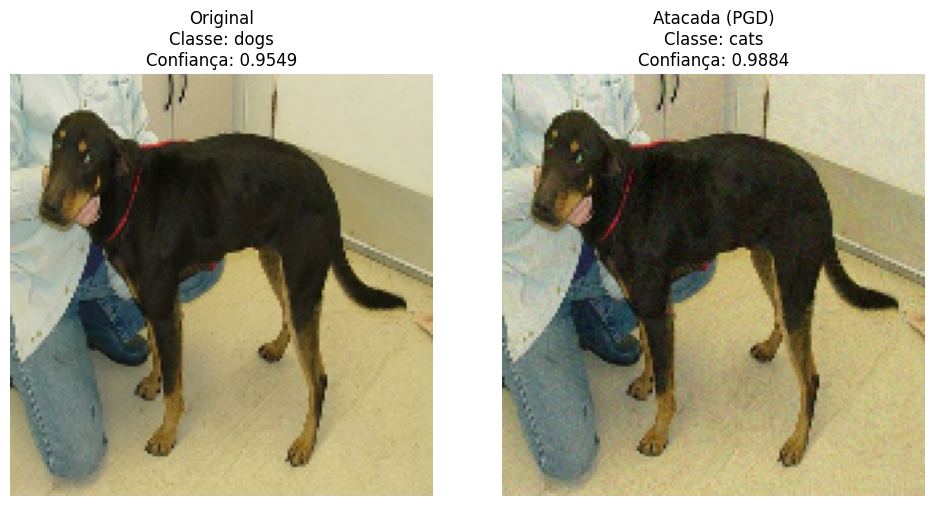

In [264]:
# Classify adversarial sample and print classification result

pred_orig = model.predict(x_input, verbose=0)[0][0]
pred_pgd  = model.predict(adv_x_pgd, verbose=0)[0][0]

class_names = train_ds.class_names

def get_label_and_conf(p):
    label = class_names[1] if p > 0.5 else class_names[0]
    conf = p if p > 0.5 else 1 - p
    return label, conf

label_o, conf_o = get_label_and_conf(pred_orig)
label_p, conf_p = get_label_and_conf(pred_pgd)

print("\n--- RESULTADOS: PGD ---")
print(f"ANTES: Classe = {label_o} | Confiança = {conf_o:.4f}")
print(f"DEPOIS (PGD): Classe = {label_p} | Confiança = {conf_p:.4f}")

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(tf.cast(x_input[0], tf.uint8).numpy())
plt.title(f"Original\nClasse: {label_o}\nConfiança: {conf_o:.4f}")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(tf.cast(adv_x_pgd[0], tf.uint8).numpy())
plt.title(f"Atacada (PGD)\nClasse: {label_p}\nConfiança: {conf_p:.4f}")
plt.axis('off')

plt.tight_layout()
plt.show()

### Exibindo uma aproximação da perturbação

In [ ]:
delta = adv_x_pgd - x_input

max_perturbation = tf.reduce_max(tf.abs(delta)).numpy()
mean_perturbation = tf.reduce_mean(tf.abs(delta)).numpy()
l2_perturbation = tf.norm(tf.reshape(delta, [-1]), ord=2).numpy()

print(f"Máxima perturbação L_inf: {max_perturbation:.4f}")
print(f"Perturbação média: {mean_perturbation:.4f}")
print(f"Perturbação L2: {l2_perturbation:.4f}")

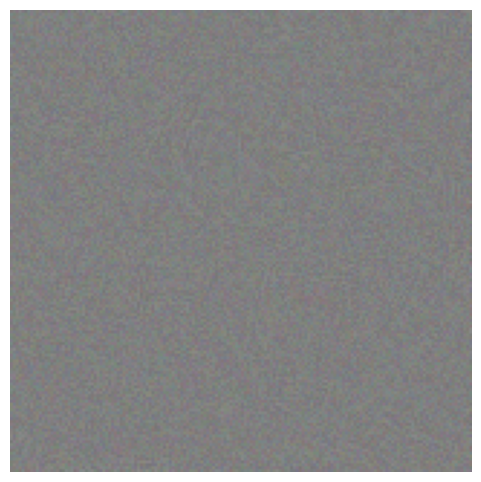

In [80]:
# Get and print adversarial perturbation
adv_f_pgd = adv_x_pgd[0].numpy().astype('float32')
org_f = x_input[0].numpy().astype('float32')

perturbacao_pgd = adv_f_pgd - org_f

img_viz_pgd = (perturbacao_pgd / 255.0) + 0.5

plt.figure(figsize=(6, 6))
plt.imshow(img_viz_pgd, cmap='gray', vmin=-0.1, vmax=0.1)
plt.axis('off')
plt.show()

### Variando hiperparâmetros PGD

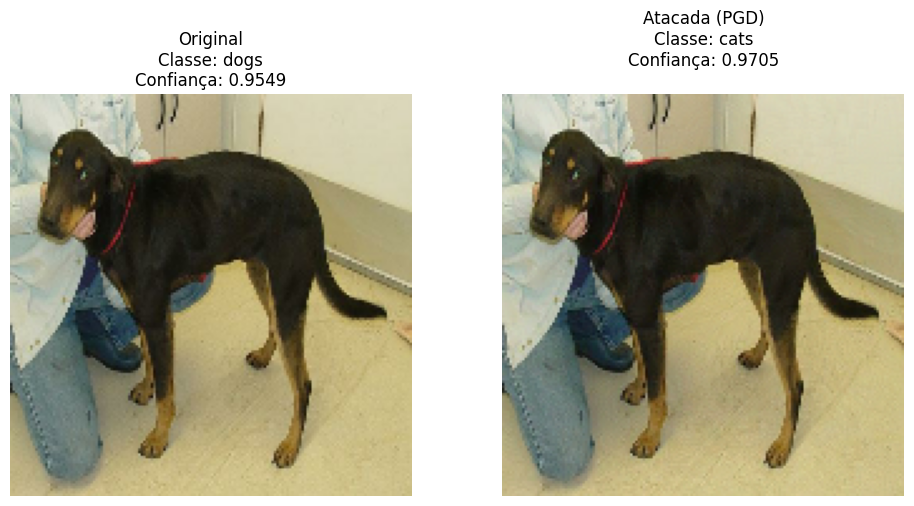

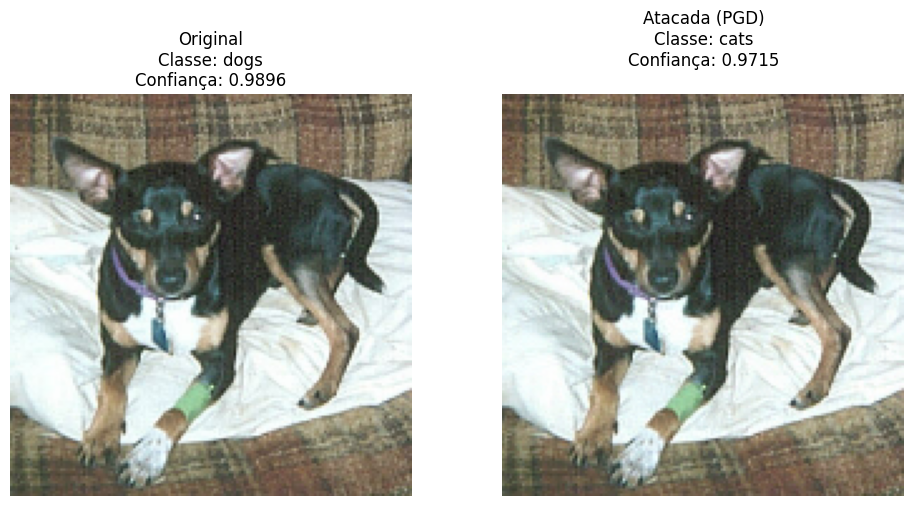

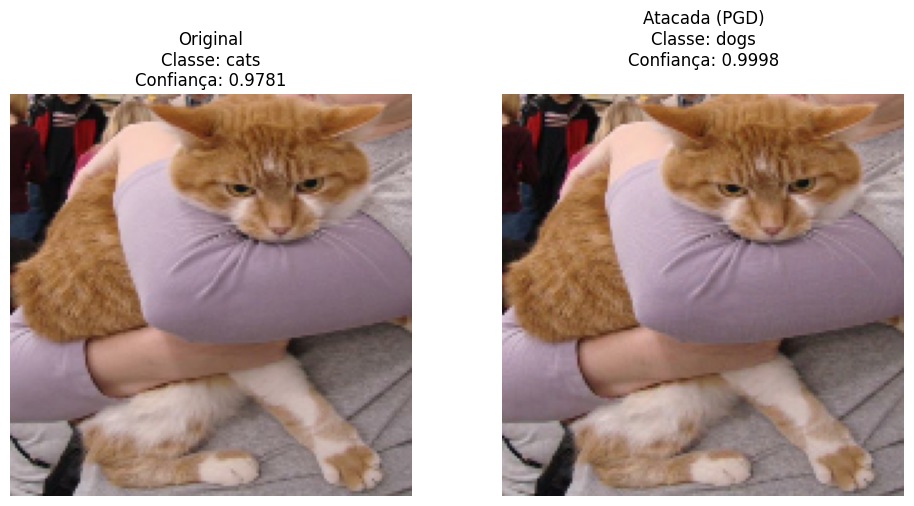

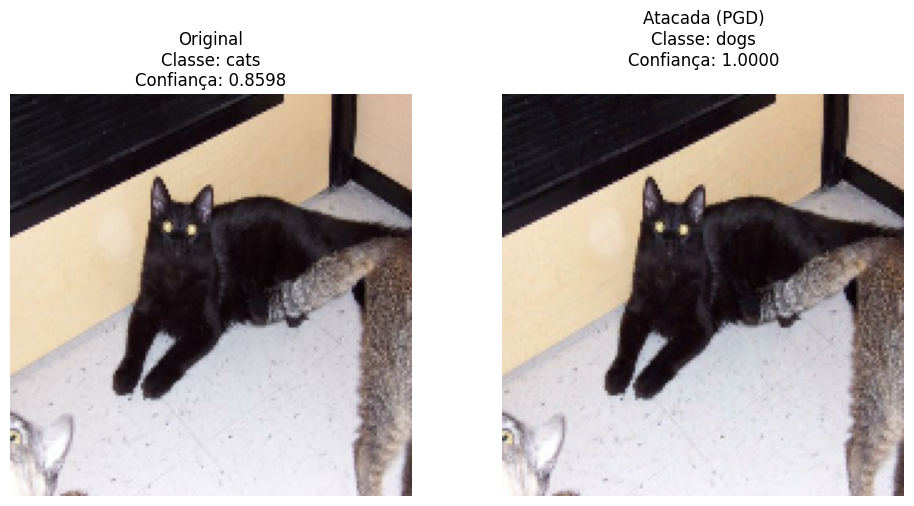

Confiança média das amostras adversariais: 0.9854
Taxa de sucesso: 1.0000
Perturbação média das amostras adversariais: 1.3032


In [ ]:
### Codigo que repete o procedimento da etapa 2 de forma automatica
# 1. pega os parametros eps, eps_iter, nb_iter
# 2. pega o modelo e o input
# 3. gera adv_x para o ataque
# 4. calcula a perturbação delta, classe e confianca e coloca numa lista
# 5. salva a imagem na pasta de saida no padrao: img[num]_[modelo]_eps[num_float]_step[num_float]_iter[num_int]_[classe_desejada]-[resultado].png
#               ex.: img01_BIM_eps0.1_step0.1_iter20_dog-no-flip
#               resultado -> no-flip (nao mudou de classe) ou to-[classe adversarial] (mudou de classe) 
# 6. ao final da execucao para o ataque, calcula a taxa de sucesso (os que resultaram na classe diferente da desejada) e confianca media

# get samples
n_inputs = 2
x_dogs, y_dogs = get_n_inputs(val_ds, 1, n=n_inputs)
x_cats, y_cats = get_n_inputs(val_ds, 0, n=n_inputs)
# x_inputs = x_dogs + x_cats
# y_trues = y_dogs + y_cats
# x_input = x_dogs[n_inputs-1]
# y_true_ch = y_dogs[n_inputs-1]

eps = 2.0
eps_iter = 0.1
nb_iter = 30
# output_dir = 'adversarial_samples_ap7.2/etapa2_variacao-eps'
# os.makedirs(output_dir, exist_ok=True)


resultados = []
hparam_list = zip(x_dogs + x_cats, y_dogs + y_cats)
for hparam in hparam_list:
    x_input, y_true_ch = hparam

    # Classe da imagem original
    pred_orig = model.predict(x_input, verbose=0)[0][0]
    label_o, conf_o = get_label_and_conf(pred_orig)

    adv_x_pgd = projected_gradient_descent(model_fn=model_wrapper, x=x_input, eps=eps, eps_iter=eps_iter, nb_iter=nb_iter, norm=np.inf, clip_min=0.0, clip_max=255.0, y=y_true_ch, rand_init=True, sanity_checks=False)
    
    delta = adv_x_pgd - x_input
    max_perturbation = tf.reduce_max(tf.abs(delta)).numpy()
    mean_perturbation = tf.reduce_mean(tf.abs(delta)).numpy()
    
    pred_adv  = model.predict(adv_x_pgd, verbose=0)[0][0]
    label_a, conf_a = get_label_and_conf(pred_adv)
    
    mudou_classe = label_a != label_o

    # Nome do arquivo
    # eps_name = f"{e:g}".replace(".", "p")
    # step_name = f"{eps_iter:g}".replace(".", "p")

    # filename = (
    #     f"img01_phase2_BIM_"
    #     f"eps{eps_name}_"
    #     f"step{step_name}_"
    #     f"iter{nb_iter}_"
    #     f"{label_o}"
    # )
    # filename += (f"_to_{label_a}.png" if mudou_classe else f"_no-flip.png")

    # output_path = os.path.join(output_dir, filename)

    # Criação da mesma figura exibida no notebook
    fig = plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(tf.cast(x_input[0], tf.uint8).numpy())
    plt.title(
        f"Original\n"
        f"Classe: {label_o}\n"
        f"Confiança: {conf_o:.4f}"
    )
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(tf.cast(adv_x_pgd[0], tf.uint8).numpy())
    plt.title(
        f"Atacada (PGD)\n"
        f"Classe: {label_a}\n"
        f"Confiança: {conf_a:.4f}\n"
    )
    plt.axis("off")

    plt.tight_layout()

    # fig.savefig(output_path, bbox_inches='tight', dpi=150)

    plt.show()
    plt.close(fig)  

    resultados.append({
        "classe_original": label_o,
        "confianca_original": conf_o,
        "classe_adversarial": label_a,
        "confianca_adversarial": conf_a,
        "mudou_classe": mudou_classe,
        "perturbacao": mean_perturbation,
    })

conf_media = mean([res["confianca_adversarial"] for res in resultados])
taxa_sucesso = sum(int(res["mudou_classe"]) for res in resultados) / len(resultados)
perturbacao_media = mean([res["perturbacao"] for res in resultados])

print(f"Confiança média das amostras adversariais: {conf_media:.4f}")
print(f"Taxa de sucesso: {taxa_sucesso:.4f}")
print(f"Perturbação média das amostras adversariais: {perturbacao_media:.4f}")

## MIM

### Importando o ataque iterativo

In [226]:
from cleverhans.tf2.attacks.momentum_iterative_method import momentum_iterative_method

### Gerando o Exemplo Adversarial

In [ ]:
# Craft adversarial sample

eps = 10.0
eps_iter = 0.5
nb_iter = 10

adv_x_mim = momentum_iterative_method(model_fn=model_wrapper, x=x_input, eps=eps, eps_iter=eps_iter, nb_iter=nb_iter, decay_factor=1.0, norm=np.inf, clip_min=0.0, clip_max=255.0, y=y_true_ch, sanity_checks=False)

### Realizando a classificação do exemplo adversarial



--- RESULTADOS: MIM ---
ANTES: Classe = dogs | Confiança = 0.9549
DEPOIS (MIM): Classe = cats | Confiança = 0.9982


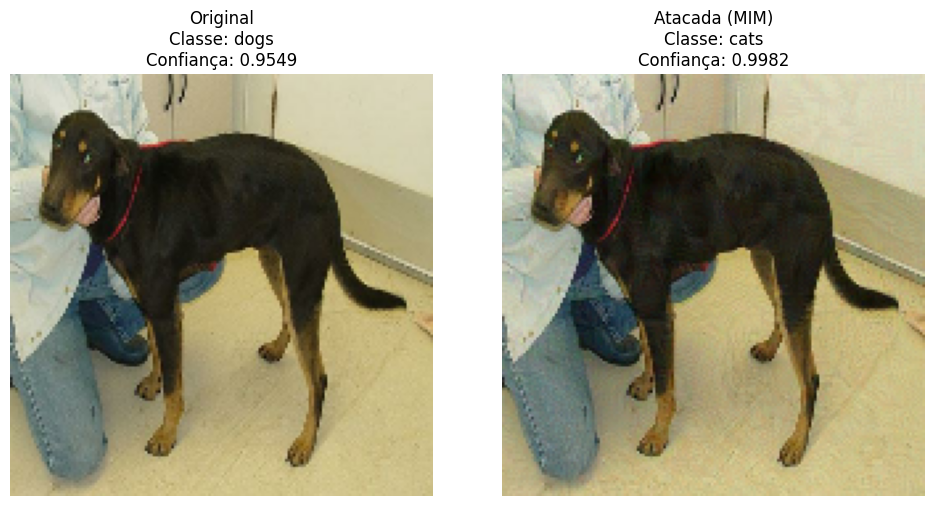

In [85]:
# Classify adversarial sample and print classification result

pred_orig = model.predict(x_input, verbose=0)[0][0]
pred_mim  = model.predict(adv_x_mim, verbose=0)[0][0]

class_names = train_ds.class_names

def get_label_and_conf(p):
    label = class_names[1] if p > 0.5 else class_names[0]
    conf = p if p > 0.5 else 1 - p
    return label, conf

label_o, conf_o = get_label_and_conf(pred_orig)
label_m, conf_m = get_label_and_conf(pred_mim)

print("\n--- RESULTADOS: MIM ---")
print(f"ANTES: Classe = {label_o} | Confiança = {conf_o:.4f}")
print(f"DEPOIS (MIM): Classe = {label_m} | Confiança = {conf_m:.4f}")

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(tf.cast(x_input[0], tf.uint8).numpy())
plt.title(f"Original\nClasse: {label_o}\nConfiança: {conf_o:.4f}")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(tf.cast(adv_x_mim[0], tf.uint8).numpy())
plt.title(f"Atacada (MIM)\nClasse: {label_m}\nConfiança: {conf_m:.4f}")
plt.axis('off')

plt.tight_layout()
plt.show()

### Exibindo uma aproximação da perturbação

In [ ]:
delta = adv_x_mim - x_input

max_perturbation = tf.reduce_max(tf.abs(delta)).numpy()
mean_perturbation = tf.reduce_mean(tf.abs(delta)).numpy()
l2_perturbation = tf.norm(tf.reshape(delta, [-1]), ord=2).numpy()

print(f"Máxima perturbação L_inf: {max_perturbation:.4f}")
print(f"Perturbação média: {mean_perturbation:.4f}")
print(f"Perturbação L2: {l2_perturbation:.4f}")

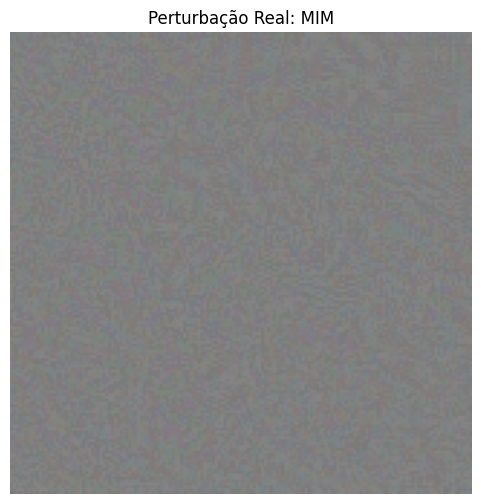

In [86]:
# Get and print adversarial perturbation
adv_f_mim = adv_x_mim[0].numpy().astype('float32')
org_f = x_input[0].numpy().astype('float32')

perturbacao_mim = adv_f_mim - org_f

img_viz_mim = (perturbacao_mim / 255.0) + 0.5

plt.figure(figsize=(6, 6))
plt.imshow(img_viz_mim, cmap='gray', vmin=-0.1, vmax=0.1)
plt.title("Perturbação Real: MIM")
plt.axis('off')
plt.show()

### Variando hiperparâmetros MIM

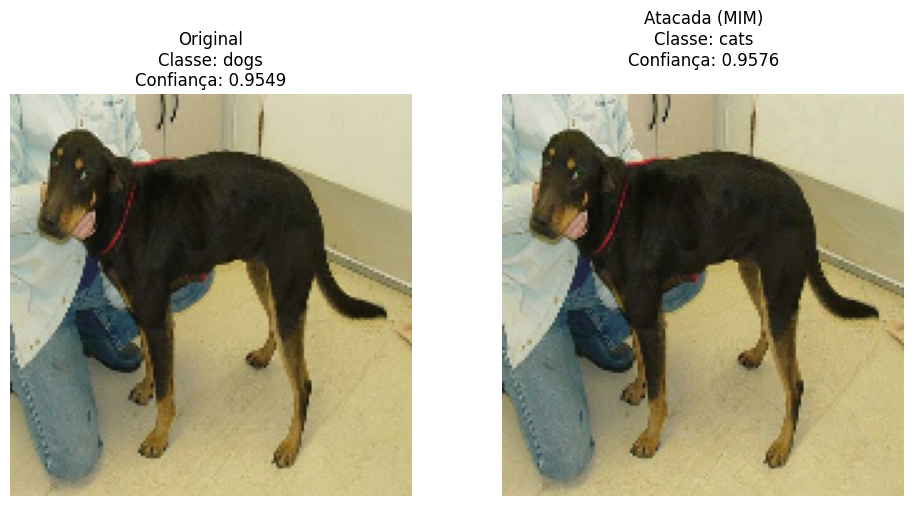

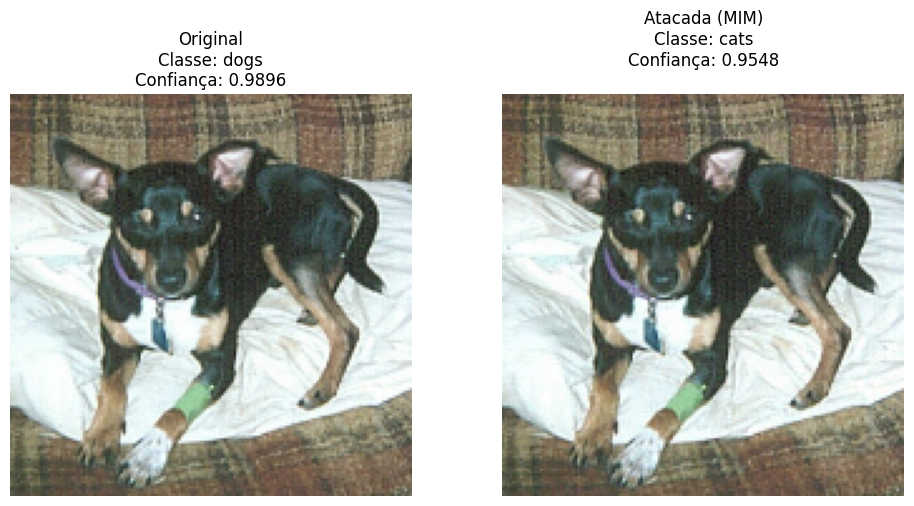

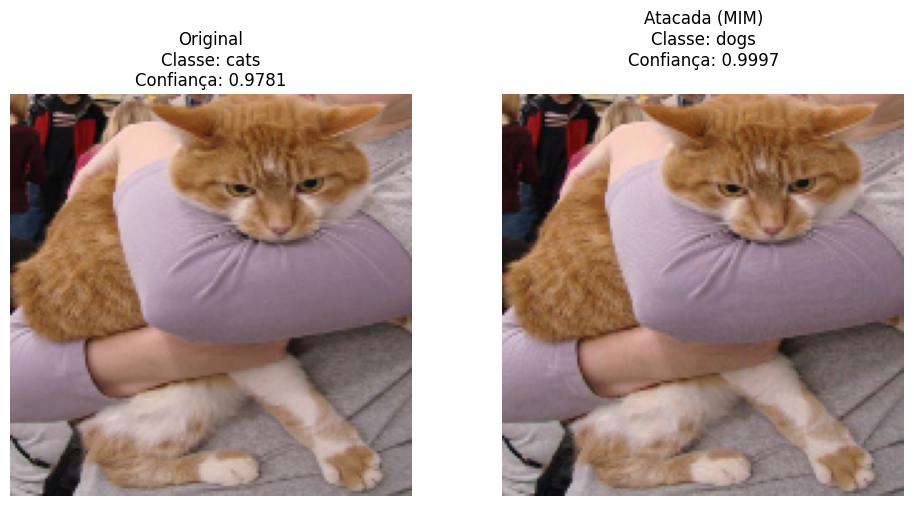

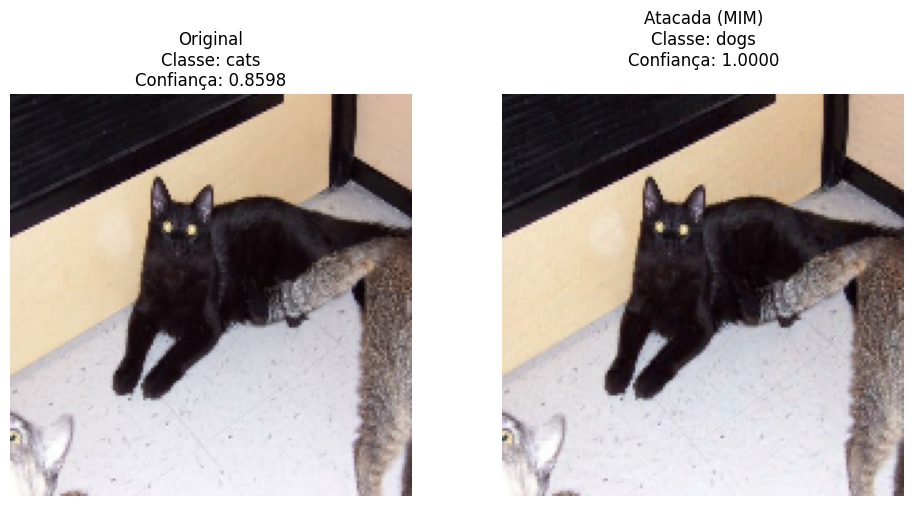

Confiança média das amostras adversariais: 0.9780
Taxa de sucesso: 1.0000
Perturbação média das amostras adversariais: 1.6143


In [276]:
### Codigo que repete o procedimento da etapa 2 de forma automatica
# 1. pega os parametros eps, eps_iter, nb_iter
# 2. pega o modelo e o input
# 3. gera adv_x para o ataque
# 4. calcula a perturbação delta, classe e confianca e coloca numa lista
# 5. salva a imagem na pasta de saida no padrao: img[num]_[modelo]_eps[num_float]_step[num_float]_iter[num_int]_[classe_desejada]-[resultado].png
#               ex.: img01_BIM_eps0.1_step0.1_iter20_dog-no-flip
#               resultado -> no-flip (nao mudou de classe) ou to-[classe adversarial] (mudou de classe) 
# 6. ao final da execucao para o ataque, calcula a taxa de sucesso (os que resultaram na classe diferente da desejada) e confianca media

# get samples
n_inputs = 2
x_dogs, y_dogs = get_n_inputs(val_ds, 1, n=n_inputs)
x_cats, y_cats = get_n_inputs(val_ds, 0, n=n_inputs)
# x_inputs = x_dogs + x_cats
# y_trues = y_dogs + y_cats
# x_input = x_dogs[n_inputs-1]
# y_true_ch = y_dogs[n_inputs-1]

eps = 2.0
eps_iter = 0.1
nb_iter = 30
# output_dir = 'adversarial_samples_ap7.2/etapa2_variacao-eps'
# os.makedirs(output_dir, exist_ok=True)


resultados = []
hparam_list = zip(x_dogs + x_cats, y_dogs + y_cats)
for hparam in hparam_list:
    x_input, y_true_ch = hparam
    
    # Classe da imagem original
    pred_orig = model.predict(x_input, verbose=0)[0][0]
    label_o, conf_o = get_label_and_conf(pred_orig)

    adv_x_mim = momentum_iterative_method(model_fn=model_wrapper, x=x_input, eps=eps, eps_iter=eps_iter, nb_iter=nb_iter, decay_factor=1.0, norm=np.inf, clip_min=0.0, clip_max=255.0, y=y_true_ch, sanity_checks=False)
    
    delta = adv_x_mim - x_input
    max_perturbation = tf.reduce_max(tf.abs(delta)).numpy()
    mean_perturbation = tf.reduce_mean(tf.abs(delta)).numpy()
    
    pred_adv  = model.predict(adv_x_mim, verbose=0)[0][0]
    label_a, conf_a = get_label_and_conf(pred_adv)
    
    mudou_classe = label_a != label_o

    # Nome do arquivo
    # eps_name = f"{e:g}".replace(".", "p")
    # step_name = f"{eps_iter:g}".replace(".", "p")

    # filename = (
    #     f"img01_phase2_BIM_"
    #     f"eps{eps_name}_"
    #     f"step{step_name}_"
    #     f"iter{nb_iter}_"
    #     f"{label_o}"
    # )
    # filename += (f"_to_{label_a}.png" if mudou_classe else f"_no-flip.png")

    # output_path = os.path.join(output_dir, filename)

    # Criação da mesma figura exibida no notebook
    fig = plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(tf.cast(x_input[0], tf.uint8).numpy())
    plt.title(
        f"Original\n"
        f"Classe: {label_o}\n"
        f"Confiança: {conf_o:.4f}"
    )
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(tf.cast(adv_x_mim[0], tf.uint8).numpy())
    plt.title(
        f"Atacada (MIM)\n"
        f"Classe: {label_a}\n"
        f"Confiança: {conf_a:.4f}\n"
    )
    plt.axis("off")

    plt.tight_layout()

    # fig.savefig(output_path, bbox_inches='tight', dpi=150)

    plt.show()
    plt.close(fig)  

    resultados.append({
        "classe_original": label_o,
        "confianca_original": conf_o,
        "classe_adversarial": label_a,
        "confianca_adversarial": conf_a,
        "mudou_classe": mudou_classe,
        "perturbacao": mean_perturbation,
    })

conf_media = mean([res["confianca_adversarial"] for res in resultados])
taxa_sucesso = sum(int(res["mudou_classe"]) for res in resultados) / len(resultados)
perturbacao_media_pixel = mean([res["perturbacao"] for res in resultados])

print(f"Confiança média das amostras adversariais: {conf_media:.4f}")
print(f"Taxa de sucesso: {taxa_sucesso:.4f}")
print(f"Perturbação média das amostras adversariais: {perturbacao_media_pixel:.4f}")